<a href="https://colab.research.google.com/github/Bubub-Tang/citra-digital-tugas2-brightnes/blob/main/pengolahan_citra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Persiapan

In [31]:
import os, io, json, hashlib, datetime, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ExifTags, ImageStat
from PIL.ExifTags import TAGS, GPSTAGS
try:
    from PIL import ImageCms
except Exception:
    ImageCms = None

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
print("Library siap dipakai")

Library siap dipakai


### Hubungkan Google Drive & muat gambar otomatis

- `FOLDER` adalah folder di Drive tempat gambar disimpan (otomatis dibuat bila belum ada).
- Isi `NAMA_FILE` bila ingin gambar tertentu. Biarkan kosong untuk memakai **gambar terbaru** di folder.
- Jika folder masih kosong, kamu akan diminta upload sekali, lalu gambarnya otomatis disimpan ke Drive.

In [32]:
# ====== PENGATURAN (boleh diubah) ======
NAMA_FOLDER = "Citra_Digital"   # nama folder di My Drive
NAMA_FILE   = ""                # Kosongkan ("") untuk mengambil gambar terbaru secara otomatis atau mengunggah baru
# =======================================

EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".gif")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DI_COLAB = True
    FOLDER = f"/content/drive/MyDrive/{NAMA_FOLDER}"
except ImportError:
    DI_COLAB = False
    FOLDER = os.environ.get("IMG_DIR", ".")   # cadangan bila dijalankan di luar Colab

os.makedirs(FOLDER, exist_ok=True)
OUT_DIR = os.path.join(FOLDER, "hasil_analisis")   # folder hasil laporan
os.makedirs(OUT_DIR, exist_ok=True)

def cari_gambar(folder):
    ada = [os.path.join(folder, f) for f in os.listdir(folder)
           if f.lower().endswith(EKSTENSI) and os.path.isfile(os.path.join(folder, f))]
    return sorted(ada, key=os.path.getmtime, reverse=True)

if NAMA_FILE:
    filename = os.path.join(FOLDER, NAMA_FILE)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File '{NAMA_FILE}' tidak ditemukan di {FOLDER}. Pastikan ekstensi file (.jpg/.png/dll) sudah ditulis dengan benar.")
else:
    kandidat = cari_gambar(FOLDER)
    if kandidat:
        filename = kandidat[0]
        if len(kandidat) > 1:
            print("Gambar lain di folder (tidak dipakai):")
            for k in kandidat[1:]:
                print("  -", os.path.basename(k))
    elif DI_COLAB:
        print(f"Folder {FOLDER} masih kosong. Silakan upload gambar (akan disimpan ke Drive):")
        from google.colab import files
        up = files.upload()
        nama = list(up.keys())[0]
        filename = os.path.join(FOLDER, nama)
        os.replace(nama, filename)   # pindahkan ke Drive
    else:
        raise FileNotFoundError(f"Tidak ada gambar di {FOLDER}")

print("\nFolder Drive      :", FOLDER)
print("Folder hasil      :", OUT_DIR)
print("File yang dianalisis:", filename)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Folder Drive      : /content/drive/MyDrive/Citra_Digital
Folder hasil      : /content/drive/MyDrive/Citra_Digital/hasil_analisis
File yang dianalisis: /content/drive/MyDrive/Citra_Digital/citra_digital.jpeg


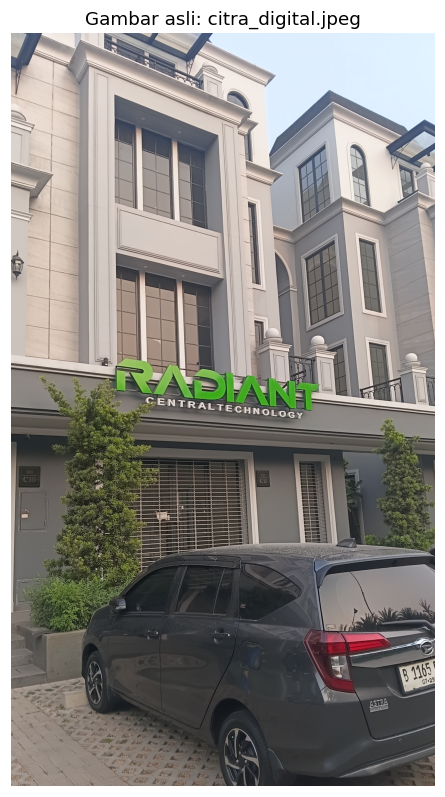

In [33]:
img = Image.open(filename)
img.load()
rgb = img.convert("RGB")
arr = np.array(rgb)            # <-- gambar berubah menjadi array angka
H, W, CH = arr.shape

plt.figure(figsize=(5, 5 * H / W if H / W < 2 else 9))
plt.imshow(arr)
plt.title(f"Gambar asli: {os.path.basename(filename)}")
plt.axis("off")
plt.show()

## A. Membuktikan Gambar adalah Kumpulan Angka (Pixel)

Komputer tidak "melihat" gambar. Gambar digital disimpan sebagai **matriks angka**. Pada gambar berwarna (RGB), setiap pixel punya 3 angka (Red, Green, Blue) dengan rentang 0 sampai 255 (8 bit).

### A1. Struktur array hasil pembacaan gambar

In [34]:
total_pixel = H * W
total_nilai = H * W * CH

print("=== BUKTI: GAMBAR = ARRAY ANGKA ===")
print(f"Tipe objek hasil baca      : {type(arr)}")
print(f"Bentuk array (shape)       : {arr.shape}  -> (tinggi, lebar, channel)")
print(f"Resolusi                   : {W} x {H} pixel")
print(f"Jumlah pixel               : {total_pixel:,}")
print(f"Jumlah channel             : {CH} (R, G, B)")
print(f"Total angka yang menyusun  : {total_nilai:,} angka")
print(f"Tipe data tiap angka       : {arr.dtype}  (8 bit, rentang 0-255)")
print(f"Nilai minimum / maksimum   : {arr.min()} / {arr.max()}")
print(f"Ukuran data mentah di RAM  : {arr.nbytes/1024/1024:.2f} MB")
print(f"Ukuran file di disk        : {os.path.getsize(filename)/1024/1024:.2f} MB  (lebih kecil karena dikompres)")
print(f"Jumlah warna unik          : {len(np.unique(arr.reshape(-1, 3), axis=0)):,}")

=== BUKTI: GAMBAR = ARRAY ANGKA ===
Tipe objek hasil baca      : <class 'numpy.ndarray'>
Bentuk array (shape)       : (4080, 2296, 3)  -> (tinggi, lebar, channel)
Resolusi                   : 2296 x 4080 pixel
Jumlah pixel               : 9,367,680
Jumlah channel             : 3 (R, G, B)
Total angka yang menyusun  : 28,103,040 angka
Tipe data tiap angka       : uint8  (8 bit, rentang 0-255)
Nilai minimum / maksimum   : 0 / 255
Ukuran data mentah di RAM  : 26.80 MB
Ukuran file di disk        : 2.13 MB  (lebih kecil karena dikompres)
Jumlah warna unik          : 146,897


### A2. Nilai angka pada pixel tertentu

,Lokasi,"Koordinat (y,x)",R,G,B,Hex
0,"Pojok kiri atas (0,0)","(0, 0)",185,181,178,#B9B5B2
1,Pojok kanan atas,"(0, 2295)",227,246,255,#E3F6FF
2,Pusat gambar,"(2040, 1148)",93,87,87,#5D5757
3,Pojok kiri bawah,"(4079, 0)",160,147,138,#A0938A
4,Pojok kanan bawah,"(4079, 2295)",111,95,82,#6F5F52


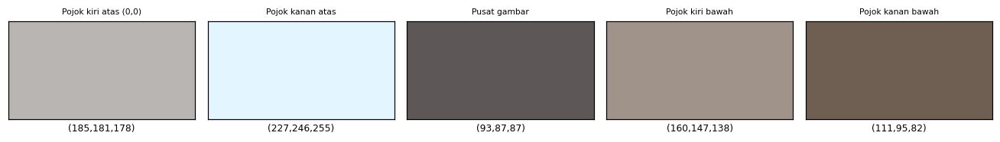

In [35]:
titik = {
    "Pojok kiri atas (0,0)": (0, 0),
    "Pojok kanan atas": (0, W - 1),
    "Pusat gambar": (H // 2, W // 2),
    "Pojok kiri bawah": (H - 1, 0),
    "Pojok kanan bawah": (H - 1, W - 1),
}

rows = []
for nama, (y, x) in titik.items():
    r, g, b = [int(v) for v in arr[y, x]]
    rows.append({"Lokasi": nama, "Koordinat (y,x)": (y, x), "R": r, "G": g, "B": b,
                 "Hex": "#{:02X}{:02X}{:02X}".format(r, g, b)})
df_titik = pd.DataFrame(rows)
display(df_titik)

# tampilkan swatch warna dari tiap titik
fig, ax = plt.subplots(1, len(rows), figsize=(12, 1.8))
for a, row in zip(ax, rows):
    a.imshow([[ [row["R"], row["G"], row["B"]] ]], aspect="auto")
    a.set_title(row["Lokasi"], fontsize=7)
    a.set_xticks([]); a.set_yticks([])
    a.set_xlabel(f'({row["R"]},{row["G"]},{row["B"]})', fontsize=8)
plt.tight_layout(); plt.show()

### A3. Zoom ke area kecil: terlihat hanya angka-angka

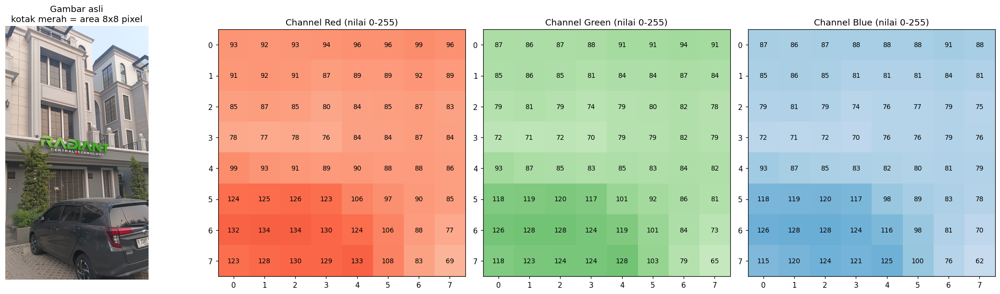

Matriks channel Red untuk area tersebut:


,x=1148,x=1149,x=1150,x=1151,x=1152,x=1153,x=1154,x=1155
y=2040,93,92,93,94,96,96,99,96
y=2041,91,92,91,87,89,89,92,89
y=2042,85,87,85,80,84,85,87,83
y=2043,78,77,78,76,84,84,87,84
y=2044,99,93,91,89,90,88,88,86
y=2045,124,125,126,123,106,97,90,85
y=2046,132,134,134,130,124,106,88,77
y=2047,123,128,130,129,133,108,83,69


In [36]:
# Ubah y0, x0 untuk memilih area lain (pojok kiri atas area yang di-zoom)
y0, x0 = H // 2, W // 2
N = 8   # ukuran area N x N pixel

patch = arr[y0:y0+N, x0:x0+N]

fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
ax[0].imshow(arr)
ax[0].add_patch(plt.Rectangle((x0-0.5, y0-0.5), N, N, fill=False, edgecolor="red", lw=2))
ax[0].set_title(f"Gambar asli\nkotak merah = area {N}x{N} pixel")
ax[0].axis("off")

for k, (nama, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")], start=1):
    m = patch[:, :, k-1]
    ax[k].imshow(m, cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
    for i in range(N):
        for j in range(N):
            v = m[i, j]
            ax[k].text(j, i, int(v), ha="center", va="center", fontsize=9,
                       color="white" if v > 150 else "black")
    ax[k].set_title(f"Channel {nama} (nilai 0-255)")
    ax[k].set_xticks(range(N)); ax[k].set_yticks(range(N))
plt.tight_layout(); plt.show()

print("Matriks channel Red untuk area tersebut:")
display(pd.DataFrame(patch[:, :, 0],
        index=[f"y={y0+i}" for i in range(N)],
        columns=[f"x={x0+j}" for j in range(N)]))

### A4. Pemisahan channel R, G, B (tiga matriks angka)

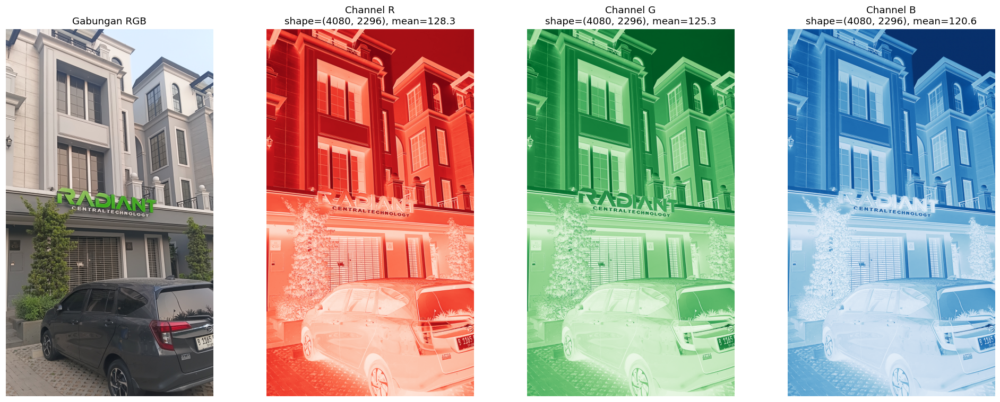

Gabungan R,G,B identik dengan array asli? True


In [37]:
R, G, B = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(18, 7))
ax[0].imshow(arr); ax[0].set_title("Gabungan RGB")
ax[1].imshow(R, cmap="Reds");   ax[1].set_title(f"Channel R\nshape={R.shape}, mean={R.mean():.1f}")
ax[2].imshow(G, cmap="Greens"); ax[2].set_title(f"Channel G\nshape={G.shape}, mean={G.mean():.1f}")
ax[3].imshow(B, cmap="Blues");  ax[3].set_title(f"Channel B\nshape={B.shape}, mean={B.mean():.1f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# bukti: menggabungkan kembali tiga matriks menghasilkan gambar yang sama persis
gabung = np.dstack([R, G, B])
print("Gabungan R,G,B identik dengan array asli?", np.array_equal(gabung, arr))

### A5. Bukti terbalik: memodifikasi angka pixel, maka gambar ikut berubah

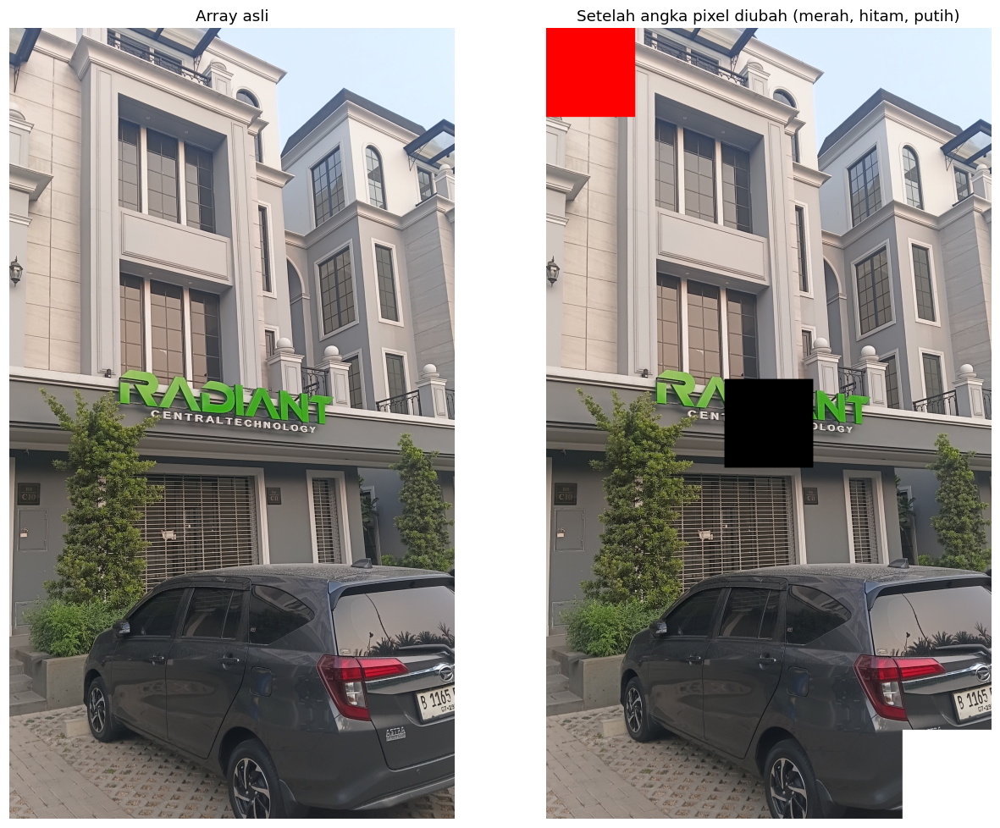

Pixel (0,0) sebelum: [185 181 178] | sesudah: [255   0   0]


In [38]:
modif = arr.copy()
s = min(H, W) // 5

# 1) blok kiri atas diubah menjadi merah murni  -> angka (255, 0, 0)
modif[0:s, 0:s] = [255, 0, 0]
# 2) blok tengah diubah menjadi hitam           -> angka (0, 0, 0)
modif[H//2 - s//2: H//2 + s//2, W//2 - s//2: W//2 + s//2] = [0, 0, 0]
# 3) blok kanan bawah diubah menjadi putih      -> angka (255, 255, 255)
modif[H-s:H, W-s:W] = [255, 255, 255]

fig, ax = plt.subplots(1, 2, figsize=(12, 9))
ax[0].imshow(arr);   ax[0].set_title("Array asli");  ax[0].axis("off")
ax[1].imshow(modif); ax[1].set_title("Setelah angka pixel diubah (merah, hitam, putih)"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("Pixel (0,0) sebelum:", arr[0, 0], "| sesudah:", modif[0, 0])

### A6. Bukti terbalik 2: membuat gambar dari angka yang kita tulis sendiri

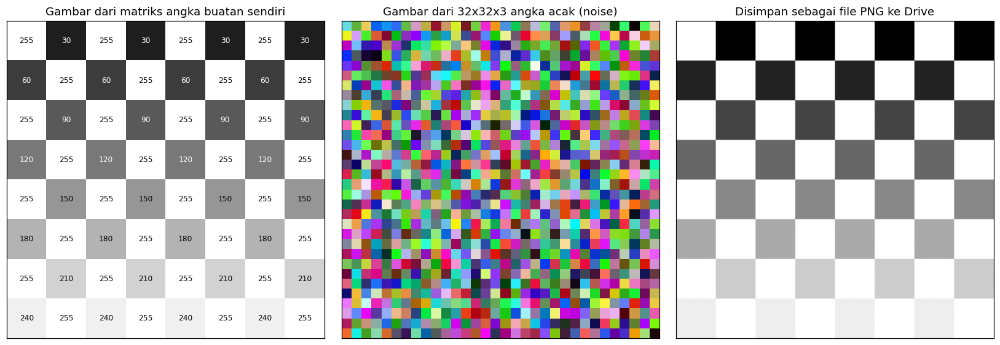

Matriks yang dipakai:
 [[255  30 255  30 255  30 255  30]
 [ 60 255  60 255  60 255  60 255]
 [255  90 255  90 255  90 255  90]
 [120 255 120 255 120 255 120 255]
 [255 150 255 150 255 150 255 150]
 [180 255 180 255 180 255 180 255]
 [255 210 255 210 255 210 255 210]
 [240 255 240 255 240 255 240 255]]


In [39]:
# Matriks 8x8 angka grayscale buatan sendiri (pola papan catur + gradasi)
manual = np.zeros((8, 8), dtype=np.uint8)
for i in range(8):
    for j in range(8):
        manual[i, j] = 255 if (i + j) % 2 == 0 else 30 * (i + 1)

# Matriks RGB acak
np.random.seed(42)
acak = np.random.randint(0, 256, size=(32, 32, 3), dtype=np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(manual, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for i in range(8):
    for j in range(8):
        v = manual[i, j]
        ax[0].text(j, i, v, ha="center", va="center", fontsize=8, color="black" if v > 128 else "white")
ax[0].set_title("Gambar dari matriks angka buatan sendiri")

ax[1].imshow(acak, interpolation="nearest")
ax[1].set_title("Gambar dari 32x32x3 angka acak (noise)")

# simpan array menjadi file gambar sungguhan
path_png = os.path.join(OUT_DIR, "gambar_dari_angka.png")
Image.fromarray(manual).resize((256, 256), Image.NEAREST).save(path_png)
ax[2].imshow(Image.open(path_png), cmap="gray")
ax[2].set_title("Disimpan sebagai file PNG ke Drive")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print("Matriks yang dipakai:\n", manual)

### A7. Perbandingan resolusi: semakin sedikit pixel, semakin terlihat kotak-kotak angka

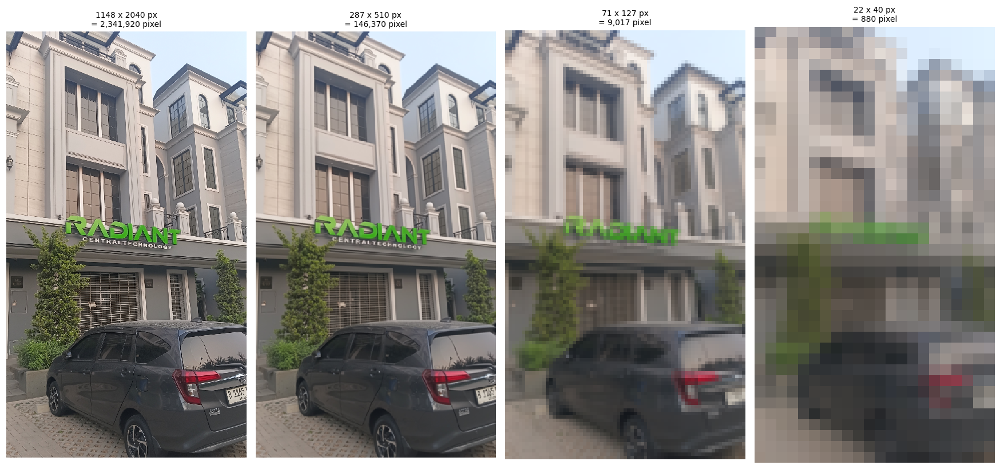

In [40]:
ukuran = [(W // 2, H // 2), (W // 8, H // 8), (W // 32, H // 32), (W // 100 or 8, H // 100 or 8)]

fig, ax = plt.subplots(1, len(ukuran), figsize=(16, 8))
for a, (w_, h_) in zip(ax, ukuran):
    kecil = rgb.resize((max(w_, 4), max(h_, 4)), Image.BILINEAR)
    a.imshow(np.array(kecil), interpolation="nearest")
    a.set_title(f"{kecil.size[0]} x {kecil.size[1]} px\n= {kecil.size[0]*kecil.size[1]:,} pixel", fontsize=9)
    a.axis("off")
plt.tight_layout(); plt.show()

## B. Ekstraksi Metadata

Metadata adalah "data tentang data": informasi tentang file dan gambar, bukan isi pixelnya. Ada beberapa lapisan: **metadata file** (sistem operasi), **metadata gambar** (header format), dan **EXIF** (data kamera, hanya ada jika tidak dihapus aplikasi).

### B1. Metadata file

In [41]:
def hitung_hash(path, algo):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

st = os.stat(filename)
fmt_waktu = lambda t: datetime.datetime.fromtimestamp(t).strftime("%Y-%m-%d %H:%M:%S")

meta_file = {
    "Nama file": os.path.basename(filename),
    "Ekstensi": os.path.splitext(filename)[1].lower(),
    "Ukuran file (bytes)": st.st_size,
    "Ukuran file (KB)": round(st.st_size / 1024, 2),
    "Ukuran file (MB)": round(st.st_size / 1024 / 1024, 3),
    "Waktu dimodifikasi (di Colab)": fmt_waktu(st.st_mtime),
    "MD5": hitung_hash(filename, "md5"),
    "SHA-256": hitung_hash(filename, "sha256"),
}

# Petunjuk dari pola nama file (mis. WhatsApp: IMG-YYYYMMDD-WAxxxx)
m = re.match(r"(IMG|VID)-(\d{8})-WA(\d+)", os.path.basename(filename))
if m:
    tgl = datetime.datetime.strptime(m.group(2), "%Y%m%d").strftime("%d %B %Y")
    meta_file["Asal (dari pola nama)"] = "WhatsApp"
    meta_file["Tanggal diterima/dikirim (dari nama)"] = tgl
    meta_file["Nomor urut WhatsApp"] = m.group(3)

df_file = pd.DataFrame(meta_file.items(), columns=["Atribut", "Nilai"])
display(df_file)

,Atribut,Nilai
0,Nama file,citra_digital.jpeg
1,Ekstensi,.jpeg
2,Ukuran file (bytes),2231378
3,Ukuran file (KB),2179.08
4,Ukuran file (MB),2.128
5,Waktu dimodifikasi (di Colab),2026-10-28 13:30:31
6,MD5,f1da29293644da9af0ed18e06ec73d98
7,SHA-256,98f32f81f99a4931e1b2a5ac851ed6b4b46f67591a6b6e5f133e58aa92e82834


### B2. Metadata gambar (dari header format)

In [42]:
dpi = img.info.get("dpi")
jfif_unit = {0: "tanpa satuan (rasio aspek)", 1: "dots per inch", 2: "dots per cm"}.get(img.info.get("jfif_unit"), "-")

from math import gcd
g_ = gcd(W, H)

meta_gambar = {
    "Format": img.format,
    "Deskripsi format": getattr(img, "format_description", "-"),
    "MIME type": Image.MIME.get(img.format, "-"),
    "Mode warna": img.mode,
    "Jumlah band/channel": len(img.getbands()),
    "Nama band": "".join(img.getbands()),
    "Lebar (px)": W,
    "Tinggi (px)": H,
    "Orientasi": "Portrait (tegak)" if H > W else ("Landscape (mendatar)" if W > H else "Persegi"),
    "Rasio aspek": f"{W//g_}:{H//g_}  ({W/H:.3f})",
    "Megapixel": round(W * H / 1e6, 2),
    "Kedalaman bit per channel": 8,
    "Kedalaman bit per pixel": 8 * len(img.getbands()),
    "DPI": dpi if dpi else "Tidak tersedia",
    "Versi JFIF": ".".join(map(str, img.info["jfif_version"])) if "jfif_version" in img.info else "-",
    "Satuan JFIF": jfif_unit,
    "Kepadatan JFIF": img.info.get("jfif_density", "-"),
    "Progressive JPEG": bool(img.info.get("progressive", False)),
    "Ada ICC profile": "icc_profile" in img.info,
    "Ada data EXIF": bool(img.getexif()),
    "Ada animasi/multi-frame": getattr(img, "is_animated", False),
}
df_gambar = pd.DataFrame(meta_gambar.items(), columns=["Atribut", "Nilai"])
display(df_gambar)

,Atribut,Nilai
0,Format,JPEG
1,Deskripsi format,JPEG (ISO 10918)
2,MIME type,image/jpeg
3,Mode warna,RGB
4,Jumlah band/channel,3
5,Nama band,RGB
6,Lebar (px),2296
7,Tinggi (px),4080
8,Orientasi,Portrait (tegak)
9,Rasio aspek,287:510 (0.563)


### B3. Metadata EXIF (kamera, waktu pengambilan, pengaturan)

In [43]:
def bersihkan(v):
    if isinstance(v, bytes):
        try:
            return v.decode(errors="ignore").strip("\x00")
        except Exception:
            return str(v)
    return v

exif = img.getexif()
exif_rows = []

if exif:
    # tag utama (IFD0)
    for tag_id, val in exif.items():
        exif_rows.append(("IFD0", TAGS.get(tag_id, tag_id), bersihkan(val)))
    # tag detail kamera (Exif IFD): ISO, exposure, aperture, dll.
    for tag_id, val in exif.get_ifd(0x8769).items():
        exif_rows.append(("Exif", TAGS.get(tag_id, tag_id), bersihkan(val)))
    # GPS
    for tag_id, val in exif.get_ifd(0x8825).items():
        exif_rows.append(("GPS", GPSTAGS.get(tag_id, tag_id), bersihkan(val)))

if exif_rows:
    df_exif = pd.DataFrame(exif_rows, columns=["Bagian", "Tag", "Nilai"])
    display(df_exif)
else:
    df_exif = pd.DataFrame(columns=["Bagian", "Tag", "Nilai"])
    print("TIDAK ADA DATA EXIF pada gambar ini.")
    print("Penyebab umum: gambar dikirim lewat WhatsApp/Telegram/media sosial, screenshot,")
    print("atau hasil edit/kompres. Aplikasi tersebut menghapus EXIF demi privasi dan ukuran file.")
    print("Untuk melihat EXIF lengkap (merek kamera, ISO, tanggal, GPS), gunakan foto asli")
    print("dari galeri/kamera yang dikirim sebagai 'Dokumen' atau lewat kabel/Google Drive.")

,Bagian,Tag,Nilai
0,IFD0,ImageWidth,2296
1,IFD0,ImageLength,4080
2,IFD0,ImageDescription,                               
3,IFD0,Make,samsung                        
4,IFD0,Model,SM-A075F                           
5,IFD0,Orientation,0
6,IFD0,YCbCrPositioning,2
7,IFD0,XResolution,72.0
8,IFD0,YResolution,72.0
9,IFD0,544,0


In [44]:
# Dekode koordinat GPS (hanya berjalan jika ada data GPS)
def ke_derajat(dms, ref):
    d, m_, s = [float(x) for x in dms]
    deg = d + m_ / 60 + s / 3600
    return -deg if ref in ("S", "W") else deg

gps = exif.get_ifd(0x8825) if exif else {}
if gps and 2 in gps and 4 in gps:
    lat = ke_derajat(gps[2], gps[1])
    lon = ke_derajat(gps[4], gps[3])
    print(f"Lokasi pengambilan foto: {lat:.6f}, {lon:.6f}")
    print(f"Google Maps: https://www.google.com/maps?q={lat},{lon}")
else:
    print("Tidak ada data GPS pada gambar ini.")

Tidak ada data GPS pada gambar ini.


### B4. ICC color profile (profil warna)

In [45]:
icc = img.info.get("icc_profile")
meta_icc = {}
if icc:
    meta_icc["Ukuran profil (bytes)"] = len(icc)
    meta_icc["Penanda"] = icc[36:40].decode(errors="ignore")  # harus 'acsp'
    try:
        prof = ImageCms.ImageCmsProfile(io.BytesIO(icc))
        meta_icc["Deskripsi"] = ImageCms.getProfileDescription(prof).strip()
        meta_icc["Pembuat"] = ImageCms.getProfileManufacturer(prof).strip() or "-"
        meta_icc["Model"] = ImageCms.getProfileModel(prof).strip() or "-"
    except Exception as e:
        meta_icc["Deskripsi"] = f"(gagal dibaca: {e})"
    display(pd.DataFrame(meta_icc.items(), columns=["Atribut", "Nilai"]))
else:
    print("Tidak ada ICC profile (gambar dianggap berwarna sRGB).")

Tidak ada ICC profile (gambar dianggap berwarna sRGB).


### B5. Detail teknis kompresi JPEG

In [46]:
meta_jpeg = {}
if img.format == "JPEG":
    from PIL import JpegImagePlugin
    sampling = JpegImagePlugin.get_sampling(img)
    meta_jpeg["Chroma subsampling"] = {0: "4:4:4", 1: "4:2:2", 2: "4:2:0", -1: "tidak diketahui"}.get(sampling, sampling)
    meta_jpeg["Jumlah tabel kuantisasi"] = len(img.quantization)
    for k, tbl in img.quantization.items():
        meta_jpeg[f"Tabel kuantisasi #{k} (rata-rata)"] = round(float(np.mean(tbl)), 2)
    meta_jpeg["Layer/komponen"] = len(img.layer) if hasattr(img, "layer") else "-"
    # perkiraan rasio kompresi
    meta_jpeg["Rasio kompresi (mentah : file)"] = f"{arr.nbytes / os.path.getsize(filename):.1f} : 1"
    display(pd.DataFrame(meta_jpeg.items(), columns=["Atribut", "Nilai"]))

    print("\nTabel kuantisasi #0 (luminance), 8x8:")
    print(np.array(img.quantization[0]).reshape(8, 8))
else:
    print("Bukan JPEG, bagian ini dilewati.")

,Atribut,Nilai
0,Chroma subsampling,4:2:0
1,Jumlah tabel kuantisasi,2
2,Tabel kuantisasi #0 (rata-rata),9.25
3,Tabel kuantisasi #1 (rata-rata),13.92
4,Layer/komponen,3
5,Rasio kompresi (mentah : file),12.6 : 1



Tabel kuantisasi #0 (luminance), 8x8:
[[ 3  2  2  3  4  6  8 10]
 [ 2  2  2  3  4  9 10  9]
 [ 2  2  3  4  6  9 11  9]
 [ 2  3  4  5  8 14 13 10]
 [ 3  4  6  9 11 17 16 12]
 [ 4  6  9 10 13 17 18 15]
 [ 8 10 12 14 16 19 19 16]
 [12 15 15 16 18 16 16 16]]


### B6. Metadata mentah (semua info dari PIL)

In [47]:
mentah = []
for k, v in img.info.items():
    if k in ("exif", "icc_profile"):
        v = f"<{len(v)} bytes>"
    mentah.append((k, v))
display(pd.DataFrame(mentah, columns=["Key", "Value"]))

,Key,Value
0,exif,<42106 bytes>
1,dpi,"(72.0, 72.0)"


## C. Analisis Brightness (Kecerahan)

Brightness diukur dari nilai pixel. Ada beberapa cara menghitungnya, jadi di sini dibandingkan:

- **Luma Rec.601** (rumus standar PIL/OpenCV): `Y = 0.299 R + 0.587 G + 0.114 B`
- **Luma Rec.709** (standar HDTV): `Y = 0.2126 R + 0.7152 G + 0.0722 B`
- **Rata-rata RGB**: `(R + G + B) / 3`
- **Value (HSV)**: nilai maksimum dari R, G, B tiap pixel

### C1. Menghitung brightness dengan beberapa metode

In [48]:
Rf, Gf, Bf = [arr[:, :, i].astype(np.float64) for i in range(3)]

gray_601 = 0.299 * Rf + 0.587 * Gf + 0.114 * Bf
gray_709 = 0.2126 * Rf + 0.7152 * Gf + 0.0722 * Bf
gray_avg = (Rf + Gf + Bf) / 3
v_hsv = arr.max(axis=2).astype(np.float64)
gray_pil = np.array(rgb.convert("L")).astype(np.float64)   # pembanding dari PIL

metode = {
    "Luma Rec.601 (manual)": gray_601,
    "Luma Rec.709": gray_709,
    "Rata-rata RGB": gray_avg,
    "Value (HSV)": v_hsv,
    "Grayscale PIL (convert 'L')": gray_pil,
}

df_br = pd.DataFrame({
    nama: {
        "Mean (0-255)": m.mean(),
        "Mean (%)": m.mean() / 255 * 100,
        "Median": np.median(m),
        "Std deviasi": m.std(),
        "Min": m.min(),
        "Max": m.max(),
    } for nama, m in metode.items()
}).T.round(2)
display(df_br)

brightness_mean = gray_601.mean()
print(f"\nBrightness utama (Rec.601): {brightness_mean:.2f} / 255  =  {brightness_mean/255*100:.2f}%")
print("Selisih dengan hasil PIL    :", round(abs(gray_601.mean() - gray_pil.mean()), 4), "(kecil, hanya beda pembulatan)")

if brightness_mean < 85:
    kategori = "GELAP"
elif brightness_mean < 170:
    kategori = "SEDANG"
else:
    kategori = "TERANG"
print("Kategori                    :", kategori)
print("Kontras (std deviasi)       :", round(gray_601.std(), 2),
      "-> rendah" if gray_601.std() < 40 else "-> sedang" if gray_601.std() < 70 else "-> tinggi")

,Mean (0-255),Mean (%),Median,Std deviasi,Min,Max
Luma Rec.601 (manual),125.69,49.29,120.85,64.18,0.0,255.0
Luma Rec.709,125.62,49.26,120.64,64.04,0.0,255.0
Rata-rata RGB,124.76,48.92,119.00,64.27,0.0,255.0
Value (HSV),133.08,52.19,128.00,67.08,0.0,255.0
Grayscale PIL (convert 'L'),125.69,49.29,121.00,64.19,0.0,255.0



Brightness utama (Rec.601): 125.69 / 255  =  49.29%
Selisih dengan hasil PIL    : 0.0049 (kecil, hanya beda pembulatan)
Kategori                    : SEDANG
Kontras (std deviasi)       : 64.18 -> sedang


### C2. Brightness per channel warna dan per pixel (grayscale)

Rata-rata per channel:
  Red   :  128.32  ( 50.3%)
  Green :  125.33  ( 49.1%)
  Blue  :  120.63  ( 47.3%)

Pixel tergelap  : (y=384, x=561) nilai 0  RGB=[0 0 2]
Pixel tercerah  : (y=657, x=1397) nilai 255  RGB=[255 255 255]

Distribusi pixel -> gelap: 32.3% | sedang: 40.3% | terang: 27.4%
Pixel hampir hitam (<=5): 0.64% | hampir putih (>=250): 0.07%


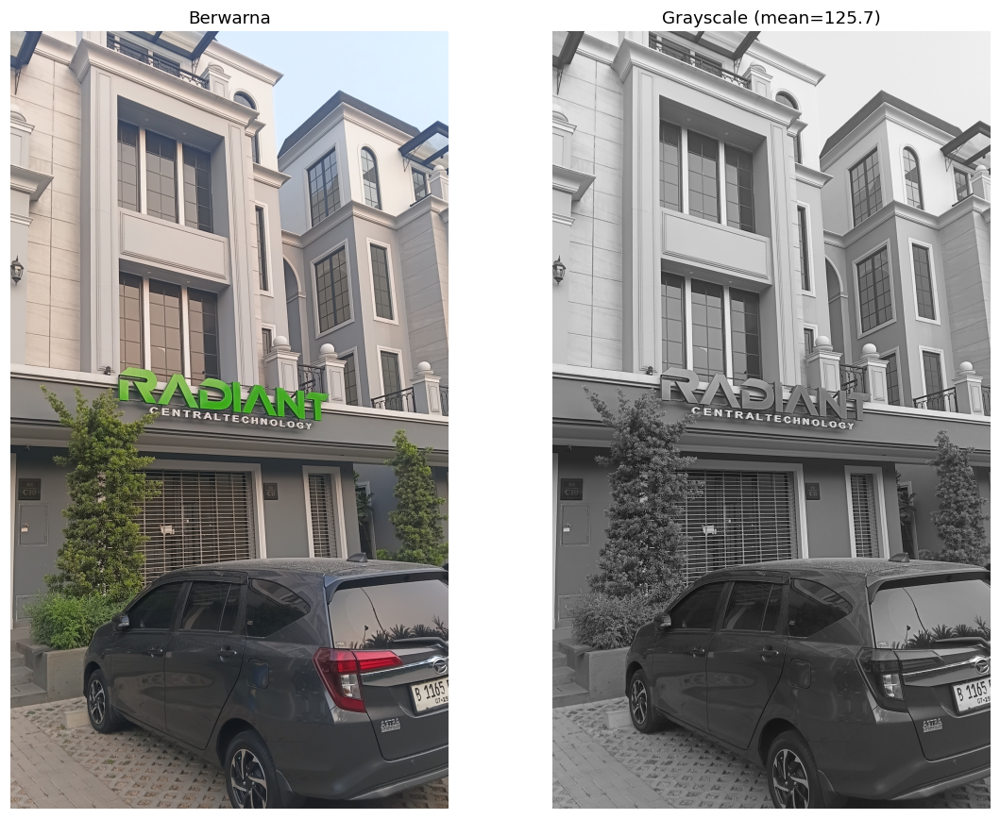

In [49]:
print("Rata-rata per channel:")
for nama, ch in zip(["Red", "Green", "Blue"], [Rf, Gf, Bf]):
    print(f"  {nama:6}: {ch.mean():7.2f}  ({ch.mean()/255*100:5.1f}%)")

gray = gray_601.astype(np.uint8)
y_min, x_min = np.unravel_index(gray.argmin(), gray.shape)
y_max, x_max = np.unravel_index(gray.argmax(), gray.shape)
print(f"\nPixel tergelap  : (y={y_min}, x={x_min}) nilai {gray[y_min, x_min]}  RGB={arr[y_min, x_min]}")
print(f"Pixel tercerah  : (y={y_max}, x={x_max}) nilai {gray[y_max, x_max]}  RGB={arr[y_max, x_max]}")

gelap = (gray < 85).mean() * 100
sedang = ((gray >= 85) & (gray < 170)).mean() * 100
terang = (gray >= 170).mean() * 100
under = (gray <= 5).mean() * 100
over = (gray >= 250).mean() * 100
print(f"\nDistribusi pixel -> gelap: {gelap:.1f}% | sedang: {sedang:.1f}% | terang: {terang:.1f}%")
print(f"Pixel hampir hitam (<=5): {under:.2f}% | hampir putih (>=250): {over:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 8))
ax[0].imshow(arr); ax[0].set_title("Berwarna"); ax[0].axis("off")
ax[1].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title(f"Grayscale (mean={brightness_mean:.1f})"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### C3. Histogram brightness dan histogram RGB

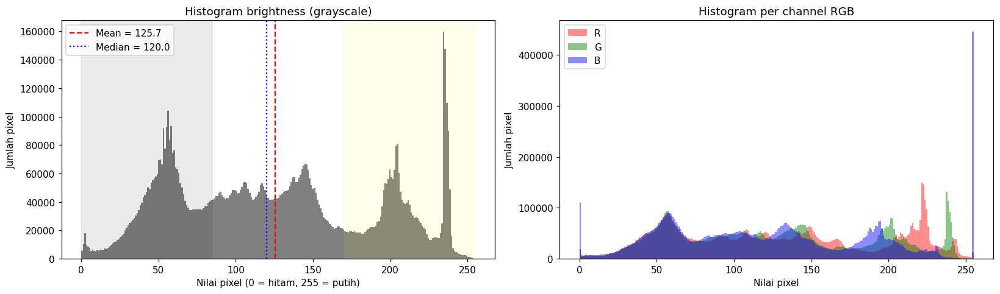

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].hist(gray.ravel(), bins=256, range=(0, 255), color="gray")
ax[0].axvline(brightness_mean, color="red", ls="--", label=f"Mean = {brightness_mean:.1f}")
ax[0].axvline(np.median(gray), color="blue", ls=":", label=f"Median = {np.median(gray):.1f}")
ax[0].axvspan(0, 85, alpha=0.08, color="black"); ax[0].axvspan(170, 255, alpha=0.08, color="yellow")
ax[0].set_title("Histogram brightness (grayscale)")
ax[0].set_xlabel("Nilai pixel (0 = hitam, 255 = putih)"); ax[0].set_ylabel("Jumlah pixel")
ax[0].legend()

for nama, warna, ch in [("R", "red", R), ("G", "green", G), ("B", "blue", B)]:
    ax[1].hist(ch.ravel(), bins=256, range=(0, 255), color=warna, alpha=0.45, label=nama)
ax[1].set_title("Histogram per channel RGB")
ax[1].set_xlabel("Nilai pixel"); ax[1].set_ylabel("Jumlah pixel")
ax[1].legend()
plt.tight_layout(); plt.show()

### C4. Peta brightness per wilayah gambar

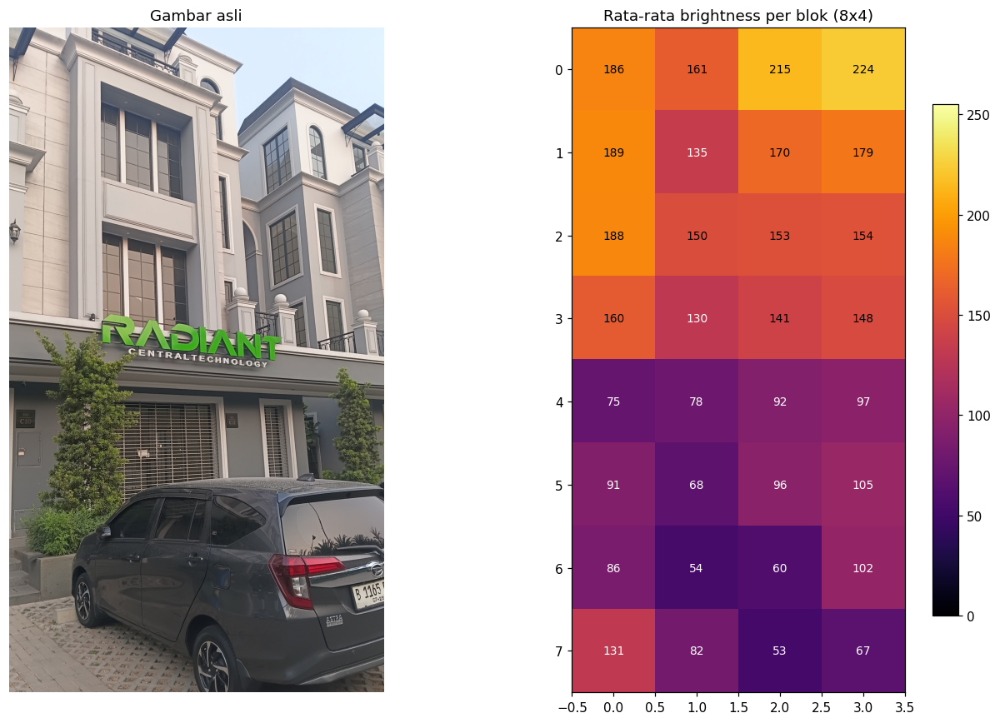

Area tercerah : baris 1, kolom 4 (mean 223.7)
Area tergelap : baris 8, kolom 3 (mean 53.3)


In [51]:
baris, kolom = 8, 4 if H > W else 8
if W > H: baris, kolom = 4, 8
h2, w2 = H // baris * baris, W // kolom * kolom
blok = gray_601[:h2, :w2].reshape(baris, h2 // baris, kolom, w2 // kolom).mean(axis=(1, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].imshow(arr); ax[0].set_title("Gambar asli"); ax[0].axis("off")
im_ = ax[1].imshow(blok, cmap="inferno", vmin=0, vmax=255)
for i in range(baris):
    for j in range(kolom):
        ax[1].text(j, i, f"{blok[i, j]:.0f}", ha="center", va="center", fontsize=9,
                   color="white" if blok[i, j] < 140 else "black")
ax[1].set_title(f"Rata-rata brightness per blok ({baris}x{kolom})")
plt.colorbar(im_, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

ib, jb = np.unravel_index(blok.argmax(), blok.shape)
ig, jg = np.unravel_index(blok.argmin(), blok.shape)
print(f"Area tercerah : baris {ib+1}, kolom {jb+1} (mean {blok[ib, jb]:.1f})")
print(f"Area tergelap : baris {ig+1}, kolom {jg+1} (mean {blok[ig, jg]:.1f})")

### C5. Bukti brightness = nilai angka: menambah/mengurangi angka mengubah kecerahan

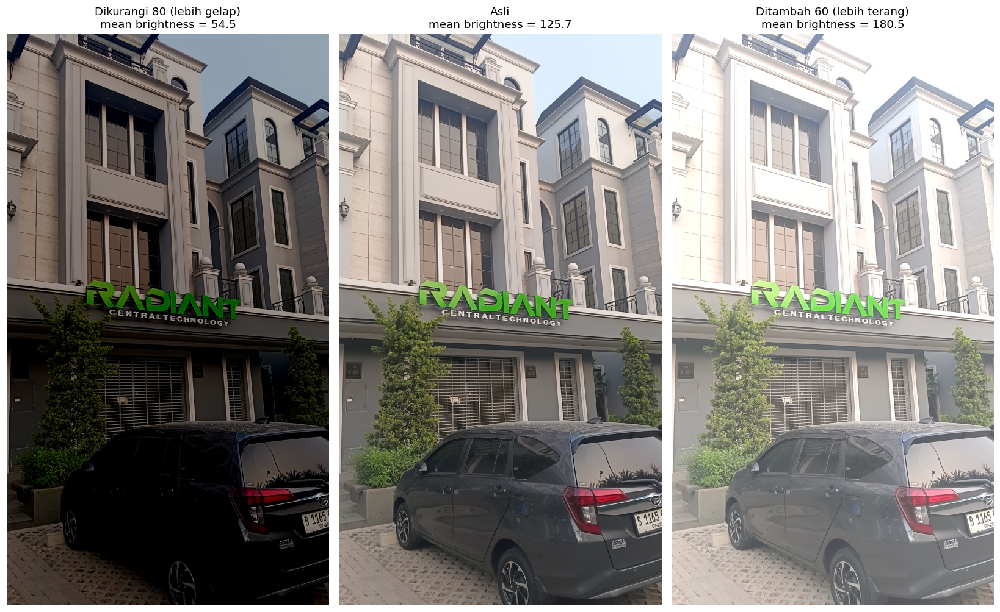

In [52]:
def ubah_brightness(a, delta):
    # tambah/kurangi delta pada semua angka, lalu batasi (clip) ke rentang 0-255
    return np.clip(a.astype(np.int16) + delta, 0, 255).astype(np.uint8)

variasi = [(-80, "Dikurangi 80 (lebih gelap)"), (0, "Asli"), (+60, "Ditambah 60 (lebih terang)")]

fig, ax = plt.subplots(1, 3, figsize=(15, 9))
for a, (d, judul) in zip(ax, variasi):
    hasil = ubah_brightness(arr, d)
    mean_ = (0.299 * hasil[..., 0] + 0.587 * hasil[..., 1] + 0.114 * hasil[..., 2]).mean()
    a.imshow(hasil)
    a.set_title(f"{judul}\nmean brightness = {mean_:.1f}")
    a.axis("off")
plt.tight_layout(); plt.show()

## D. Ringkasan & Ekspor Laporan

In [53]:
ringkasan = {
    "file": os.path.basename(filename),
    "format": img.format,
    "mode_warna": img.mode,
    "resolusi": f"{W}x{H}",
    "total_pixel": int(total_pixel),
    "total_angka": int(total_nilai),
    "tipe_data": str(arr.dtype),
    "ukuran_file_kb": round(os.path.getsize(filename) / 1024, 2),
    "md5": meta_file["MD5"],
    "ada_exif": bool(exif_rows),
    "mean_R": round(float(Rf.mean()), 2),
    "mean_G": round(float(Gf.mean()), 2),
    "mean_B": round(float(Bf.mean()), 2),
    "brightness_mean_0_255": round(float(brightness_mean), 2),
    "brightness_persen": round(float(brightness_mean / 255 * 100), 2),
    "brightness_median": round(float(np.median(gray)), 2),
    "kategori_brightness": kategori,
    "kontras_std": round(float(gray_601.std()), 2),
}
display(pd.DataFrame(ringkasan.items(), columns=["Parameter", "Nilai"]))

path_json = os.path.join(OUT_DIR, "laporan_citra.json")
path_xlsx = os.path.join(OUT_DIR, "laporan_metadata.xlsx")
with open(path_json, "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, indent=2, ensure_ascii=False)

# Fungsi bantu untuk membersihkan karakter null bytes '\x00' dari dataframe
def bersihkan_df_dari_null_bytes(df):
    return df.apply(lambda col: col.map(lambda x: x.replace("\x00", "") if isinstance(x, str) else x))

# Bersihkan semua dataframe sebelum diekspor ke Excel
df_file_clean = bersihkan_df_dari_null_bytes(df_file)
df_gambar_clean = bersihkan_df_dari_null_bytes(df_gambar)
df_exif_clean = bersihkan_df_dari_null_bytes(df_exif)
df_br_clean = bersihkan_df_dari_null_bytes(df_br)
df_titik_clean = bersihkan_df_dari_null_bytes(df_titik.astype({"Koordinat (y,x)": str}))
df_ringkasan_clean = bersihkan_df_dari_null_bytes(pd.DataFrame(ringkasan.items(), columns=["Parameter", "Nilai"]))

# simpan semua tabel ke satu file Excel
with pd.ExcelWriter(path_xlsx) as xw:
    df_file_clean.to_excel(xw, sheet_name="Metadata File", index=False)
    df_gambar_clean.to_excel(xw, sheet_name="Metadata Gambar", index=False)
    df_exif_clean.to_excel(xw, sheet_name="EXIF", index=False)
    df_br_clean.to_excel(xw, sheet_name="Brightness")
    df_titik_clean.to_excel(xw, sheet_name="Sampel Pixel", index=False)
    df_ringkasan_clean.to_excel(xw, sheet_name="Ringkasan", index=False)

print("Laporan tersimpan di Google Drive:")
print("  ", path_json)
print("  ", path_xlsx)

,Parameter,Nilai
0,file,citra_digital.jpeg
1,format,JPEG
2,mode_warna,RGB
3,resolusi,2296x4080
4,total_pixel,9367680
5,total_angka,28103040
6,tipe_data,uint8
7,ukuran_file_kb,2179.08
8,md5,f1da29293644da9af0ed18e06ec73d98
9,ada_exif,True


Laporan tersimpan di Google Drive:
   /content/drive/MyDrive/Citra_Digital/hasil_analisis/laporan_citra.json
   /content/drive/MyDrive/Citra_Digital/hasil_analisis/laporan_metadata.xlsx


In [54]:
# (Opsional) unduh juga ke komputer, hanya di Colab
try:
    from google.colab import files
    files.download(path_xlsx)
    files.download(path_json)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>